# O-RAN edge DDoS (PCAP) — detection + FedAvg

Raw packet captures from a 5G O-RAN testbed over ~40 s windows: benign TCP/HTTP vs TCP-SYN flood vs UDP flood, across **5 edge agents**. The loader parses the PCAPs with a dependency-free libpcap reader and derives flow-level features; each agent becomes a **federated client** so raw captures never leave their agent.

In [1]:
# --- bootstrap: make the `trustoran` engineering package importable ---------
import sys, pathlib
REPO = pathlib.Path.cwd().resolve()
while not (REPO / "py" / "trustoran").exists() and REPO != REPO.parent:
    REPO = REPO.parent
sys.path.insert(0, str(REPO / "py"))

%matplotlib inline
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

from trustoran import config as C
from trustoran.data import build_dataset, train_test_split_dataset
from trustoran.data.loaders import available_datasets
from trustoran.models import make_model
from trustoran.pipeline.engine import TrustPipeline, PILLARS, DATASET_PROFILES
from trustoran.viz import plotting as VZ
from trustoran.trust import explainability as EX, robustness as RB, fairness as FA, privacy as PR

print("repo root :", REPO)
print("datasets  :", available_datasets())
print("pillars   :", PILLARS)

repo root : E:\可信AI
datasets  : ['cci_a1sd', 'cci_a1sd_binary', 'ddos_pcap', 'vran_energy', 'vran_application', 'vran_computing']
pillars   : ('explainability', 'robustness', 'fairness', 'privacy')


## Flow features from raw PCAPs

`trustoran.data.pcap` decodes Ethernet → IPv4 → TCP/UDP in pure Python and aggregates per-flow statistics (packet/byte counts, inter-arrival, flag ratios, payload ratio).

{'name': 'ddos_pcap', 'task': 'classification', 'n_samples': 64, 'n_features': 21, 'feature_names': ['n_packets', 'n_bytes', 'duration', 'pkt_rate', 'avg_pkt_len', 'std_pkt_len', 'min_pkt_len', 'max_pkt_len', 'mean_iat_ms', 'std_iat_ms', 'max_iat_ms', 'tcp_ratio', 'udp_ratio', 'syn_ratio', 'synack_ratio', 'ack_ratio', 'rst_ratio', 'http_ratio', 'n_src_ips', 'n_dst_ports', 'payload_ratio'], 'class_names': ['benign', 'tcp_syn_flood', 'udp_flood'], 'class_counts': {'benign': 54, 'tcp_syn_flood': 5, 'udp_flood': 5}, 'group_attrs': ['agent', 'role'], 'meta': {'source': 'O-RAN DDoS PCAP', 'files': ['Agent_1/online_preprocessing_10_without_gtp.pcap', 'Agent_1/online_preprocessing_11_without_gtp.pcap', 'Agent_1/online_preprocessing_12_without_gtp.pcap', 'Agent_1/online_preprocessing_13_without_gtp.pcap', 'Agent_1/online_preprocessing_14_without_gtp.pcap', 'Agent_1/online_preprocessing_15_without_gtp.pcap', 'Agent_1/online_preprocessing_16_without_gtp.pcap', 'Agent_1/online_preprocessing_17_wit

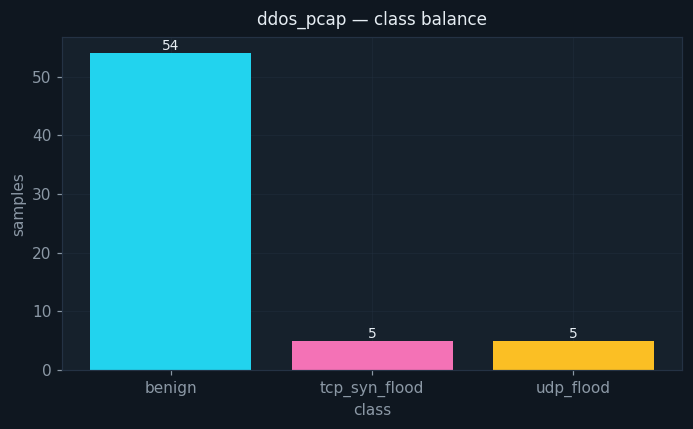

In [2]:
ds = build_dataset("ddos_pcap", seed=42)
print(ds.describe())
print("features:", ds.feature_names)
print("groups  :", {k: len(np.unique(v)) for k, v in ds.groups.items()})
display(VZ.fig_class_distribution(ds))

base metrics: {'accuracy': 1.0, 'f1_macro': 1.0}


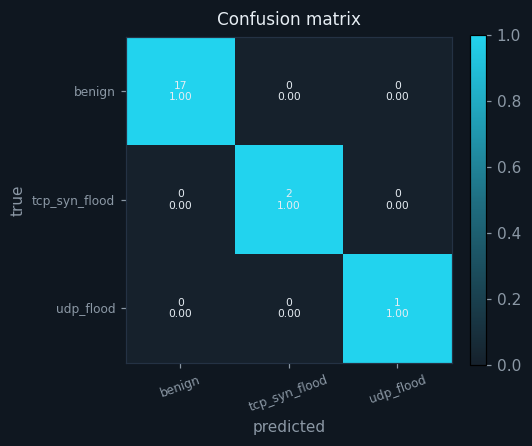

In [3]:
split = train_test_split_dataset(ds, test_size=0.3, seed=42, scale=True)
model = make_model("random_forest", split.train.task, split.feature_names,
                   split.train.class_names, params={"n_estimators": 200})
model.fit(split.X_train, split.y_train)
print("base metrics:", {k: round(v,4) for k,v in model.score(split.X_test, split.y_test).items()})
display(VZ.fig_confusion_matrix(split.y_test, model.predict(split.X_test), ds.class_names))

## Explainability — which flow signals betray a flood?

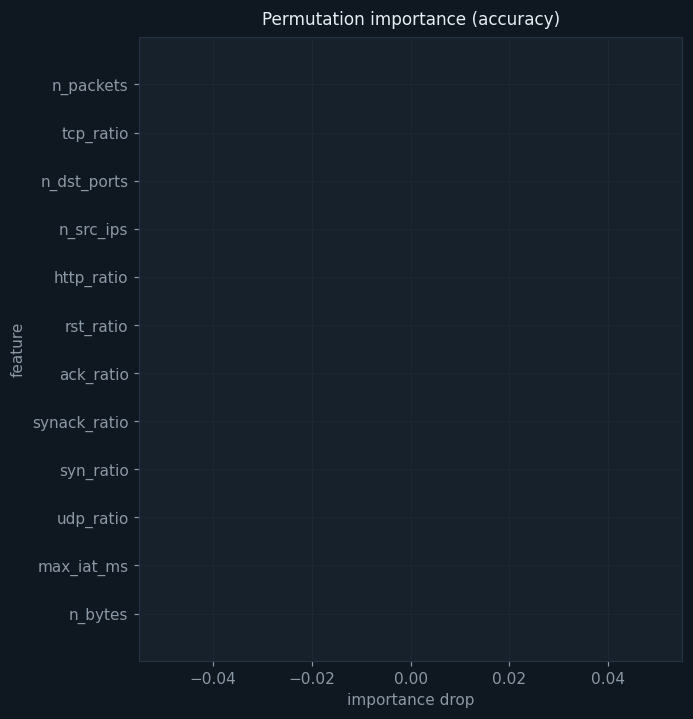

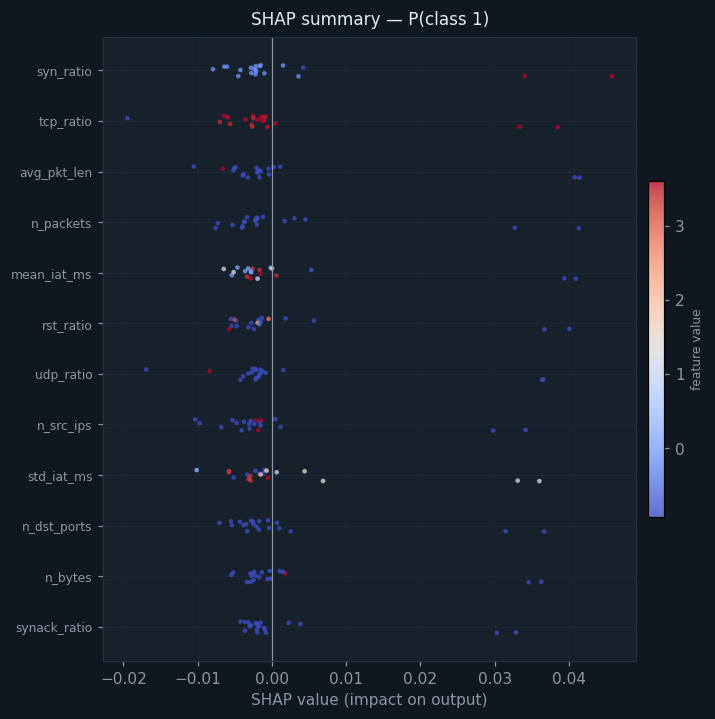

In [4]:
gi = EX.global_importance(model, split.X_test, split.y_test, n_repeats=8, seed=42)
display(VZ.fig_permutation_importance(gi))
rng = np.random.default_rng(0)
bg = split.X_train[rng.choice(len(split.X_train), min(100, len(split.X_train)), replace=False)]
ex = split.X_test[rng.choice(len(split.X_test), min(40, len(split.X_test)), replace=False)]
sh = EX.shap_explain(model, ex, bg, target_class=1, seed=42)
display(VZ.fig_shap_summary(sh))

## Robustness — evading the edge IDS

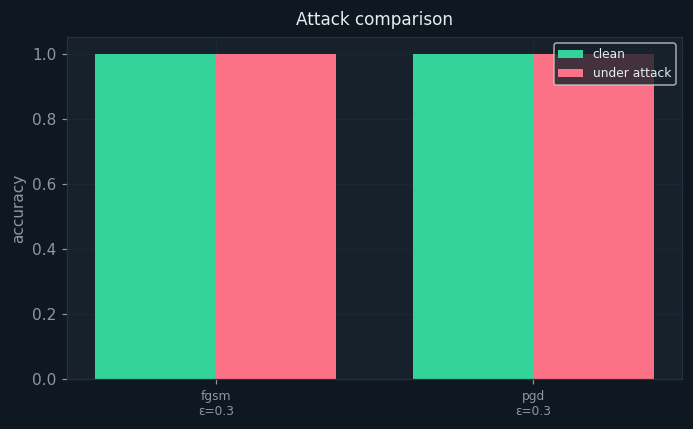

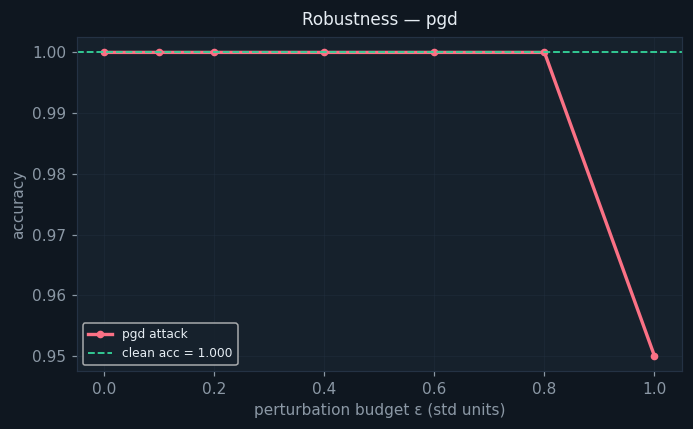

In [5]:
Xs, ys = split.X_test, split.y_test
attacks = [RB.evaluate_attack(model, Xs, ys, "fgsm", 0.3, ds.class_names),
           RB.evaluate_attack(model, Xs, ys, "pgd", 0.3, ds.class_names, seed=42)]
display(VZ.fig_attack_comparison(attacks))
display(VZ.fig_robustness_curve(RB.robustness_curve(model, Xs, ys, "pgd",
          eps_range=(0.0,0.1,0.2,0.4,0.6,0.8,1.0), seed=42)))

## Fairness — parity across the 5 agents

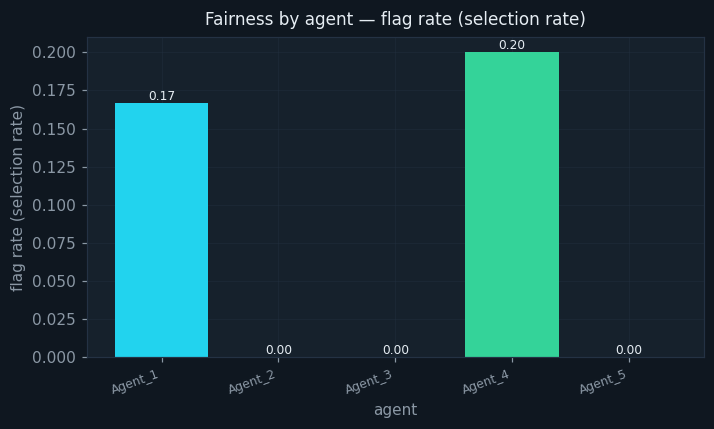

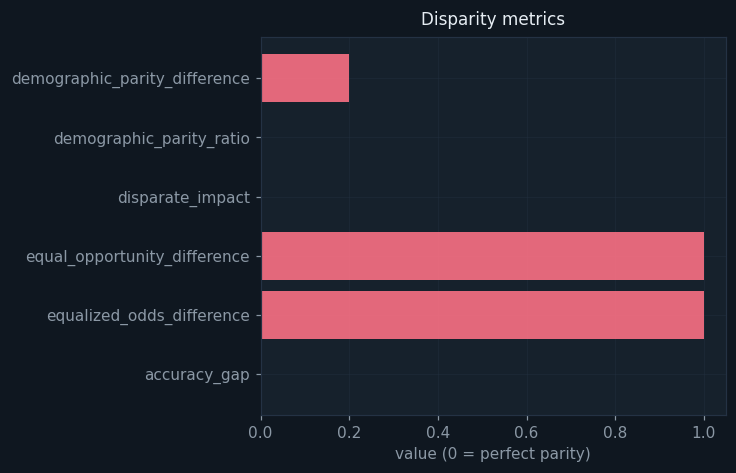

In [6]:
groups = split.test.group_values("agent")
fr = FA.analyze_fairness(model, split.X_test, split.y_test, groups, "agent",
                         task=split.train.task, positive_class=1, class_names=ds.class_names)
display(VZ.fig_fairness_groups(fr))
display(VZ.fig_fairness_metrics(fr))

## Privacy — FedAvg across agents (the headline demo)

Each agent trains locally; only weight updates are averaged. `fedavg` compares **federated** vs **centralised** (pool everything) vs **local-only** (one agent alone).

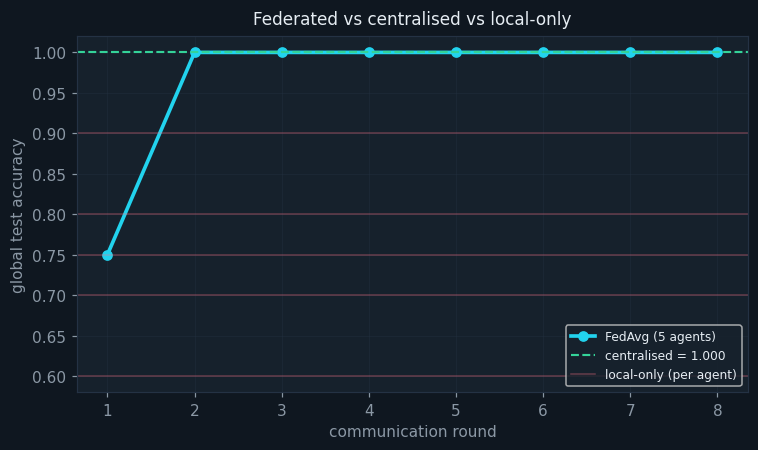

federated : 1.0
centralised: 1.0
local-only : [0.9, 0.8, 0.7, 0.6, 0.75]


In [7]:
agents = split.train.group_values("agent")
clients = {}
for a in np.unique(agents):
    m = agents == a
    clients[str(a)] = (split.X_train[m], split.y_train[m])
K = int(split.y_train.max() + 1)
fr_fed = PR.fedavg(clients, split.X_test, split.y_test, K=K, n_rounds=8,
                   local_epochs=6, batch=16, hidden=24, seed=42)
display(VZ.fig_fedavg(fr_fed))
print("federated :", round(fr_fed.federated_accuracies[-1], 3))
print("centralised:", round(fr_fed.centralized_accuracy, 3))
print("local-only :", [round(a,3) for a in fr_fed.local_only_accuracies])

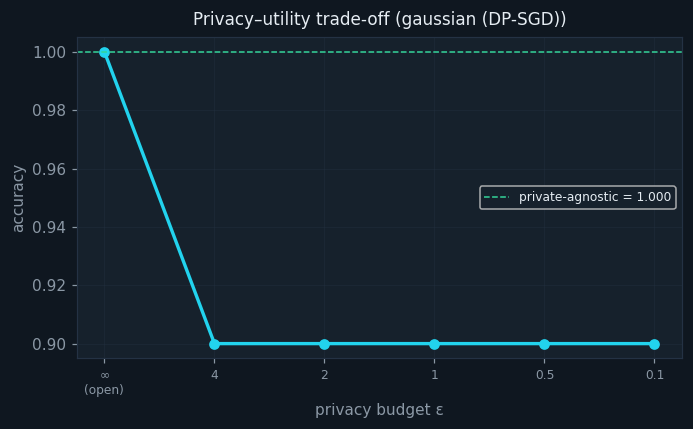

In [8]:
dp = PR.privacy_utility_curve(split.X_train, split.y_train, split.X_test, split.y_test,
                              split.train.task, eps_range=(float("inf"),4.0,2.0,1.0,0.5,0.1),
                              epochs=25, hidden=24, seed=42)
display(VZ.fig_dp_curve(dp))